# Setup de los datos

Genera `data/processed/{train,val,test}` a partir de `data/lol_champions_visual_data`. La justificación de cada decisión está en el reporte.

In [1]:
import hashlib
import random
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path("..")   # los notebooks se corren desde notebooks/

RAW_DIR = ROOT / "data" / "lol_champions_visual_data"
OUT_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "docs" / "figures"   # gráficas que usa el reporte
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
MIN_SPLASH = 15          # mínimo de splash arts limpias para conservar un campeón (ver sección 3)
VAL_FRAC = 0.15
TEST_FRAC = 0.15
USE_BW_IN_TRAIN = True   # las copias en blanco y negro solo se usan en train
RESIZE_HEIGHT = 384      # alto de las imágenes guardadas (se conserva la proporción)

random.seed(SEED)

def savefig(name):
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print(RAW_DIR, RAW_DIR.exists())

../data/lol_champions_visual_data True


## 1. Inventario del dataset original

Cada carpeta es un campeón, con íconos de habilidades (`00`–`04`, PNG de 64×64) y splash arts (`05` en adelante, JPG de 1215×717). Cada imagen tiene una copia en grises con sufijo `_bw`.

In [2]:
rows = []
for champ_dir in sorted(p for p in RAW_DIR.iterdir() if p.is_dir()):
    for f in sorted(champ_dir.iterdir()):
        if f.name.startswith("."):
            continue
        with Image.open(f) as im:
            w, h = im.size
            mode = im.mode
        rows.append({
            "champion": champ_dir.name,
            "file": f.name,
            "path": f,
            "bw": f.stem.endswith("_bw"),
            "kind": "icon" if w <= 128 else "splash",
            "width": w,
            "height": h,
            "mode": mode,
        })

df = pd.DataFrame(rows)
print("Campeones:", df.champion.nunique())
print("Archivos:", len(df))
df.groupby(["kind", "bw"]).size().unstack()

Campeones: 172
Archivos: 5872


bw,False,True
kind,,
icon,860,860
splash,2076,2076


In [3]:
# Cada imagen a color debe tener su pareja _bw
color = df[~df.bw]
bw_names = set(zip(df[df.bw].champion, df[df.bw].file))
missing = [
    (r.champion, r.file) for r in color.itertuples()
    if (r.champion, r.path.stem + "_bw" + r.path.suffix) not in bw_names
]
print("Imágenes a color sin copia _bw:", len(missing))
print("Tamaños (solo color):")
print(color.groupby(["kind", "width", "height"]).size())

Imágenes a color sin copia _bw: 0
Tamaños (solo color):
kind    width  height
icon    64     64         860
splash  1215   717       2076
dtype: int64


count    172.000000
mean      12.069767
std        4.799587
min        2.000000
25%        9.000000
50%       12.500000
75%       15.250000
max       23.000000
dtype: float64

Menos splash arts:
 champion
ambessa    2
zaahen     2
yunara     2
hwei       3
mel        3
aurora     3
smolder    3
ksante     4


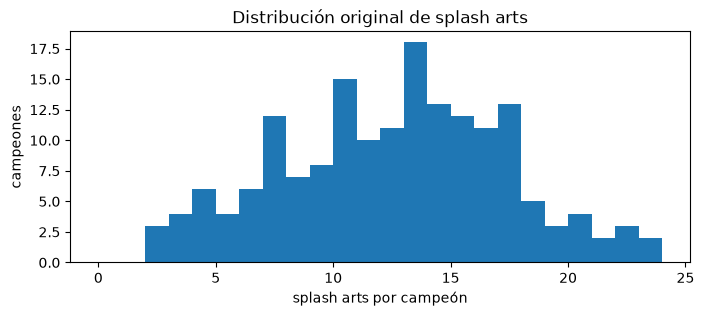

In [4]:
splash = df[(df.kind == "splash") & (~df.bw)].copy()
per_champ = splash.groupby("champion").size().sort_values()

print(per_champ.describe())
print("\nMenos splash arts:\n", per_champ.head(8).to_string())

plt.figure(figsize=(8, 3))
plt.hist(per_champ, bins=range(0, per_champ.max() + 2))
plt.xlabel("splash arts por campeón")
plt.ylabel("campeones")
plt.title("Distribución original de splash arts")
savefig("distribucion_splash")
plt.show()

Solo se usan las splash arts; los íconos se descartan.

## 2. Splash arts grupales y duplicados

Se calculan dos huellas por imagen: MD5 (archivos idénticos) y *average hash* de 16×16 (imágenes casi idénticas aunque cambie la compresión). Si una huella se repite:
- en varios campeones, la imagen es **grupal** y se excluyen todas sus copias;
- dentro de un mismo campeón, es **duplicada** y se conserva solo la primera.

In [5]:
def md5(path):
    return hashlib.md5(path.read_bytes()).hexdigest()

def average_hash(path, size=16):
    with Image.open(path) as im:
        g = np.asarray(im.convert("L").resize((size, size)), dtype=np.float32)
    return (g > g.mean()).tobytes().hex()

splash["md5"] = splash.path.map(md5)
splash["ahash"] = splash.path.map(average_hash)

group_files = set()
dup_files = set()
for col in ["md5", "ahash"]:
    for _, g in splash.groupby(col):
        if len(g) < 2:
            continue
        if g.champion.nunique() > 1:
            group_files.update(g.index)          # compartida entre campeones
        else:
            dup_files.update(g.sort_values("file").index[1:])  # se conserva la primera

dup_files -= group_files
print("Splash grupales (en varios campeones):", len(group_files))
print("Duplicadas dentro de un campeón:", len(dup_files))
print("\nCampeones más afectados por grupales:")
print(splash.loc[sorted(group_files)].champion.value_counts().head(8).to_string())

Splash grupales (en varios campeones): 174
Duplicadas dentro de un campeón: 18

Campeones más afectados por grupales:
champion
rakan           7
xayah           7
ezreal          4
gnar            4
gragas          4
olaf            4
syndra          4
twisted_fate    4


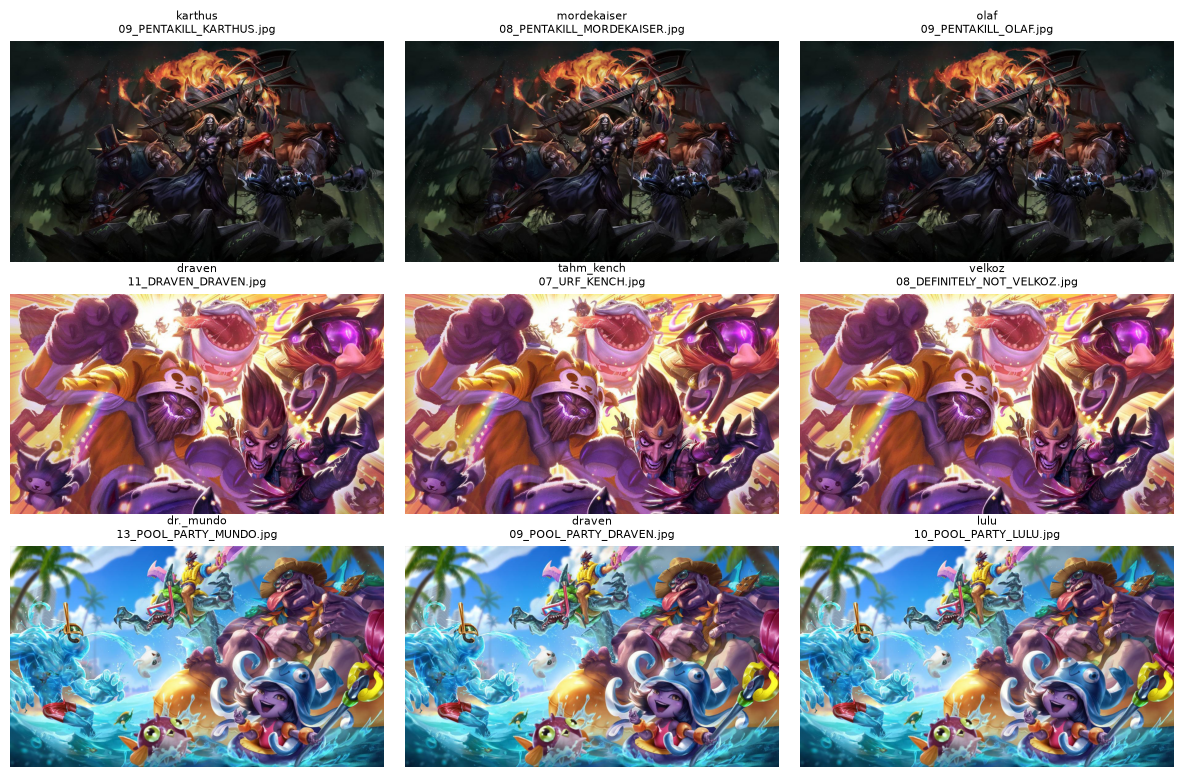

In [6]:
# Ejemplos: la misma imagen etiquetada como campeones distintos
examples = [g for _, g in splash.loc[sorted(group_files)].groupby("md5") if len(g) > 2][:3]

fig, axes = plt.subplots(len(examples), 3, figsize=(12, 2.6 * len(examples)))
for row, g in zip(np.atleast_2d(axes), examples):
    for ax, r in zip(row, g.itertuples()):
        ax.imshow(Image.open(r.path))
        ax.set_title(f"{r.champion}\n{r.file}", fontsize=8)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
savefig("splash_grupales")
plt.show()

## 3. Filtro de campeones

Se conservan los campeones con al menos `MIN_SPLASH` splash arts limpias. La tabla muestra cuántas clases e imágenes quedan con cada umbral.

In [7]:
excluded_idx = group_files | dup_files
clean = splash.drop(index=sorted(excluded_idx))
clean_counts = clean.groupby("champion").size()

pd.DataFrame({
    "mínimo": [5, 8, 10, 12, 15],
    "campeones": [(clean_counts >= k).sum() for k in [5, 8, 10, 12, 15]],
    "imágenes": [clean_counts[clean_counts >= k].sum() for k in [5, 8, 10, 12, 15]],
})

,mínimo,campeones,imágenes
0,5,159,1842
1,8,126,1635
2,10,107,1470
3,12,77,1152
4,15,38,648


In [8]:
kept_champs = sorted(clean_counts[clean_counts >= MIN_SPLASH].index)
dropped_champs = sorted(set(splash.champion) - set(kept_champs))
data = clean[clean.champion.isin(kept_champs)].copy()

print(f"Con MIN_SPLASH = {MIN_SPLASH}:")
print(f"  campeones conservados: {len(kept_champs)}")
print(f"  campeones descartados: {len(dropped_champs)}")
print(f"  imágenes: {len(data)} (media {data.groupby('champion').size().mean():.1f} por campeón)")

Con MIN_SPLASH = 15:
  campeones conservados: 38
  campeones descartados: 134
  imágenes: 648 (media 17.1 por campeón)


## 4. División en train / val / test

Split estratificado por campeón: ~15% a `val`, ~15% a `test` (mínimo 1 imagen en cada uno) y el resto a `train`.
- La splash base (`05_<CAMPEÓN>`) siempre va a `train`; el resto se reparte al azar.
- La copia `_bw` sigue a su imagen a color y solo se guarda en `train`, para que no haya fuga de información entre splits.

In [9]:
def split_counts(n):
    n_val = max(1, round(n * VAL_FRAC))
    n_test = max(1, round(n * TEST_FRAC))
    return n - n_val - n_test, n_val, n_test

data["is_base"] = data.file.str.startswith("05_")

data["split"] = ""
for champ, g in data.groupby("champion"):
    base = list(g.index[g.is_base])       # splash original: siempre a train
    rest = list(g.index[~g.is_base])
    random.shuffle(rest)
    idx = base + rest
    n_train, n_val, _ = split_counts(len(idx))
    data.loc[idx[:n_train], "split"] = "train"
    data.loc[idx[n_train:n_train + n_val], "split"] = "val"
    data.loc[idx[n_train + n_val:], "split"] = "test"

print("Splash base por split:", data[data.is_base].split.value_counts().to_dict())
data.groupby("split").size()

Splash base por split: {'train': 38}


split
test      95
train    458
val       95
dtype: int64

### 4.1 Balance de clases

split  train  val  test
min     11.0  2.0   2.0
mean    12.1  2.5   2.5
max     15.0  3.0   3.0


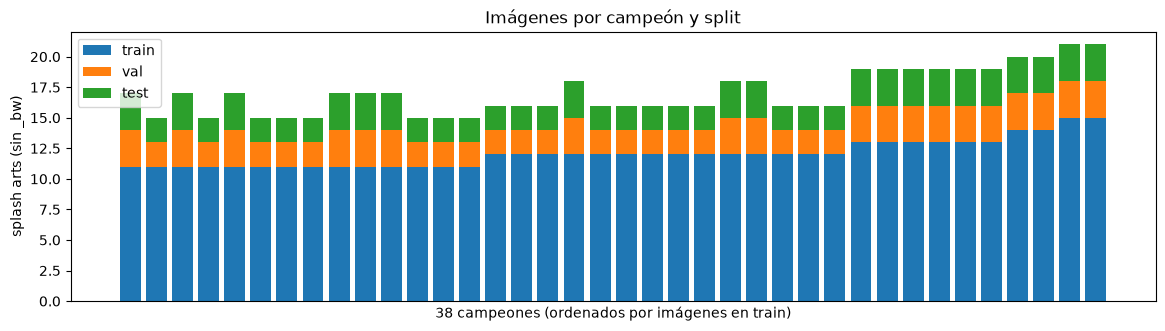

In [10]:
counts = data.groupby(["champion", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
print(counts.describe().loc[["min", "mean", "max"]].round(1))

order = counts.train.sort_values().index
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(range(len(order)), counts.loc[order, "train"], label="train")
ax.bar(range(len(order)), counts.loc[order, "val"], bottom=counts.loc[order, "train"], label="val")
ax.bar(range(len(order)), counts.loc[order, "test"],
       bottom=counts.loc[order, "train"] + counts.loc[order, "val"], label="test")
ax.set_xticks([])
ax.set_xlabel(f"{len(order)} campeones (ordenados por imágenes en train)")
ax.set_ylabel("splash arts (sin _bw)")
ax.set_title("Imágenes por campeón y split")
ax.legend()
savefig("balance_splits")
plt.show()

## 5. Preprocesamiento

### 5.1 De imagen ancha a cuadrada

Comparación visual de tres formas de llevar la splash a 224×224: estirar, recortar el centro y letterbox.

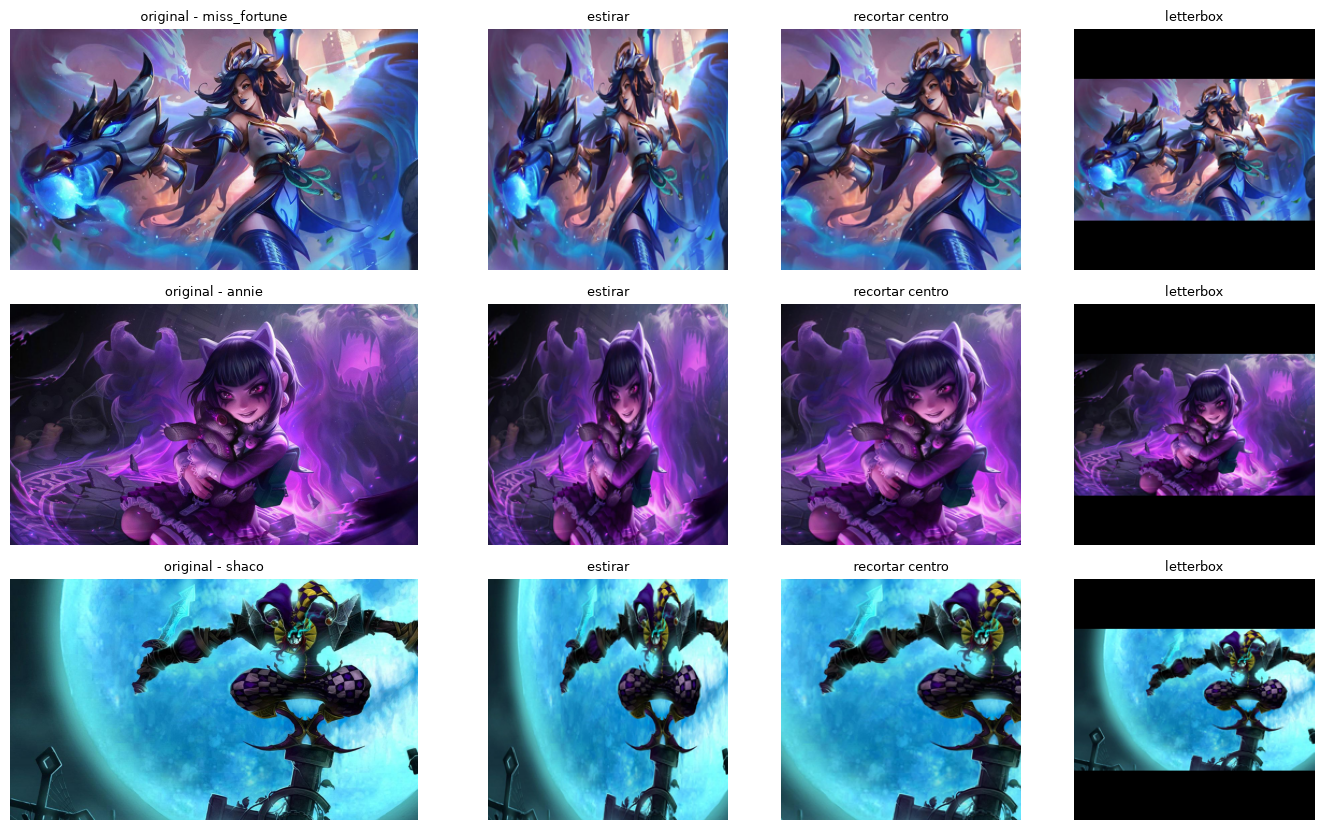

In [11]:
SIZE = 224

def stretch(im):
    return im.resize((SIZE, SIZE))

def center_crop(im):
    w, h = im.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return im.crop((left, top, left + s, top + s)).resize((SIZE, SIZE))

def letterbox(im):
    w, h = im.size
    scale = SIZE / max(w, h)
    small = im.resize((round(w * scale), round(h * scale)))
    canvas = Image.new("RGB", (SIZE, SIZE))
    canvas.paste(small, ((SIZE - small.width) // 2, (SIZE - small.height) // 2))
    return canvas

samples = data[data.split == "train"].sample(3, random_state=SEED)
methods = [("original", lambda im: im), ("estirar", stretch),
           ("recortar centro", center_crop), ("letterbox", letterbox)]

fig, axes = plt.subplots(len(samples), len(methods), figsize=(14, 2.8 * len(samples)),
                         gridspec_kw={"width_ratios": [1.7, 1, 1, 1]})
for row, r in zip(axes, samples.itertuples()):
    im = Image.open(r.path).convert("RGB")
    for ax, (name, fn) in zip(row, methods):
        ax.imshow(fn(im))
        ax.set_title(f"{name}" + (f" - {r.champion}" if name == "original" else ""), fontsize=9)
        ax.axis("off")
plt.tight_layout()
savefig("formas_cuadrado")
plt.show()

Las imágenes se guardan conservando su proporción; cada modelo hace su propia conversión en `training.ipynb`.

### 5.2 Reducción de tamaño

Se guardan con alto `RESIZE_HEIGHT` (≈651×384) usando LANCZOS. Además se escriben `manifest.csv` (split de cada archivo) y `excluded.csv` (imágenes excluidas y motivo).

In [12]:
def save_resized(src, dst):
    with Image.open(src) as im:
        w, h = im.size
        new_size = (round(w * RESIZE_HEIGHT / h), RESIZE_HEIGHT)
        im.resize(new_size, Image.LANCZOS).save(dst, quality=92)

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)

manifest = []
for r in data.itertuples():
    dest = OUT_DIR / r.split / r.champion
    dest.mkdir(parents=True, exist_ok=True)
    save_resized(r.path, dest / r.file)
    manifest.append({"split": r.split, "champion": r.champion, "file": r.file})

    bw_path = r.path.with_name(r.path.stem + "_bw" + r.path.suffix)
    if r.split == "train" and USE_BW_IN_TRAIN:
        save_resized(bw_path, dest / bw_path.name)
        manifest.append({"split": r.split, "champion": r.champion, "file": bw_path.name})

manifest = pd.DataFrame(manifest)
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)

excluded = splash.loc[sorted(excluded_idx), ["champion", "file"]].copy()
excluded["reason"] = ["grupal" if i in group_files else "duplicada" for i in excluded.index]
excluded.to_csv(OUT_DIR / "excluded.csv", index=False)

manifest.groupby("split").agg(imagenes=("file", "size"), campeones=("champion", "nunique"))

,imagenes,campeones
split,,
test,95,38
train,916,38
val,95,38


In [13]:
def folder_mb(path):
    return sum(f.stat().st_size for f in path.rglob("*") if f.is_file()) / 1e6

orig_files = [r.path for r in data.itertuples()]
orig_files += [p.with_name(p.stem + "_bw" + p.suffix)
               for p, s in zip(data.path, data.split) if s == "train" and USE_BW_IN_TRAIN]
print(f"Tamaño con imágenes originales: {sum(p.stat().st_size for p in orig_files) / 1e6:.0f} MB")
print(f"Tamaño en {OUT_DIR.name}/: {folder_mb(OUT_DIR):.0f} MB")

Tamaño con imágenes originales: 123 MB
Tamaño en processed/: 80 MB


## 6. Verificación final

In [14]:
# Verificación: ninguna imagen (ni casi-duplicado) se repite entre splits
check = data[["split", "md5", "ahash"]]
for col in ["md5", "ahash"]:
    leaks = check.groupby(col).split.nunique()
    print(f"{col}: huellas presentes en más de un split = {(leaks > 1).sum()}")

# Todas las clases en todos los splits
for s in ["train", "val", "test"]:
    n = len(list((OUT_DIR / s).iterdir()))
    print(f"{s}: {n} carpetas de campeón")

md5: huellas presentes en más de un split = 0
ahash: huellas presentes en más de un split = 0
train: 38 carpetas de campeón
val: 38 carpetas de campeón
test: 38 carpetas de campeón


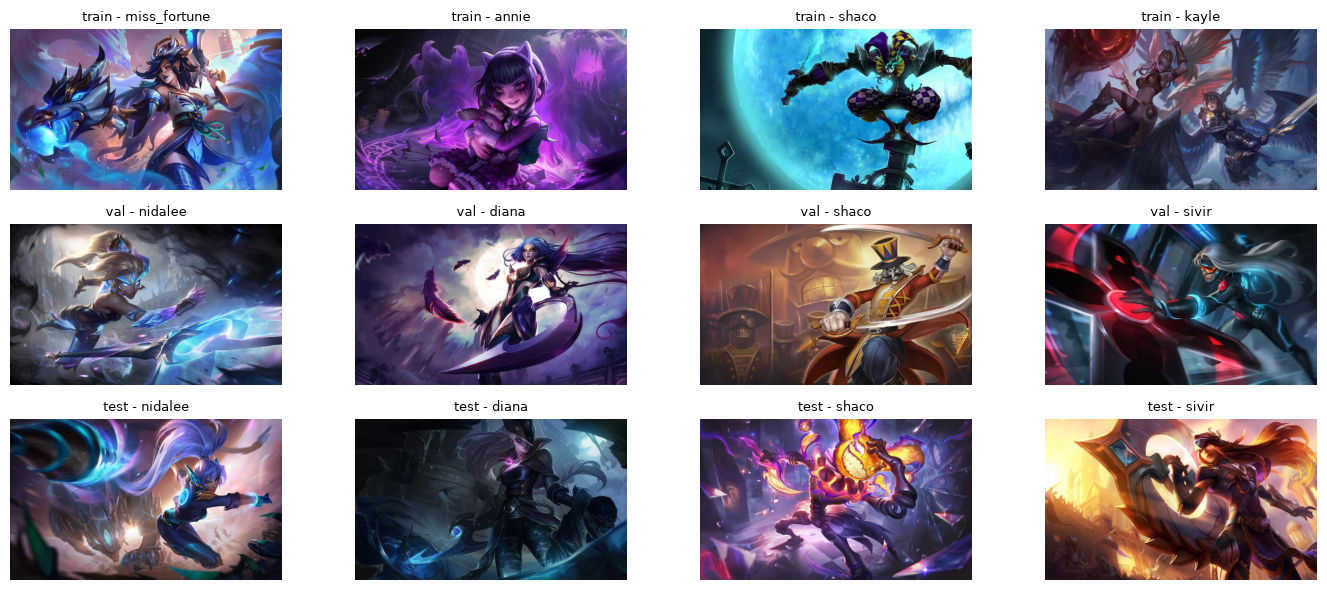

In [15]:
# Ejemplos de las imágenes finales en cada split
fig, axes = plt.subplots(3, 4, figsize=(14, 6))
for row, s in zip(axes, ["train", "val", "test"]):
    picks = manifest[(manifest.split == s) & ~manifest.file.str.contains("_bw")].sample(4, random_state=SEED)
    for ax, r in zip(row, picks.itertuples()):
        ax.imshow(Image.open(OUT_DIR / s / r.champion / r.file))
        ax.set_title(f"{s} - {r.champion}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

**Siguiente paso:** `training.ipynb`.